<a href="https://colab.research.google.com/github/luizcodedthat/deteccao-gestos/blob/main/Gestos_em_Foto.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Micro-Projeto de Visão Computacional — Gestos em Foto

**Capacitação em Visão Computacional** · IFPE · INPaR · Financiamento FACEPE

**Título:** Gestos em Foto — classificação geométrica de três gestos de mão

**Resumo.** O sistema recebe uma fotografia de uma mão e classifica o gesto em `palma_aberta`, `punho_fechado` ou `paz` (indicador e médio estendidos). O MediaPipe Hand Landmarker localiza a mão e entrega 21 pontos (landmarks). A classificação é própria: regras geométricas sobre os ângulos das articulações dos dedos. O limiar das regras é calibrado em um conjunto e a avaliação final usa outro, com pessoas diferentes. Os dados vêm do HaGRID.

**Equipe:** Lucas Lins e Luiz Eduardo

## 1. Problema

Reconhecer, a partir de uma foto, se a mão está em palma aberta, punho fechado ou paz, com um método simples, explicável e portável para um app Android (Flutter).

**Hipótese.** Em um dedo estendido, a articulação PIP (a do meio do dedo) fica quase reta e o ângulo é grande. Em um dedo dobrado, o ângulo é pequeno. Comparar esse ângulo com um limiar diz quais dedos estão estendidos, e a combinação dos dedos define o gesto.

**Escopo.**
- É um classificador heurístico baseado em geometria, sobre um detector de landmarks pré-treinado. Não há treino de modelo.
- O polegar fica fora das regras.
- São três poses estáticas simplificadas. O sistema não reconhece linguagem de sinais.

## 2. Preparação

Bibliotecas: `mediapipe` (API Tasks), `opencv-python-headless`, `numpy`, `pandas`, `matplotlib`, `Pillow`, `scikit-learn` e `huggingface_hub`. Não usa GPU.

Se o Colab exibir o aviso de reinicialização após a instalação, reinicie a sessão (*Ambiente de execução → Reiniciar sessão*) e continue a partir da célula de imports.

In [ ]:
!pip -q install mediapipe opencv-python-headless pillow scikit-learn huggingface_hub

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 MB 15.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.7/137.7 kB 10.2 MB/s eta 0:00:00


In [ ]:
import os
import re
import json
import math
import shutil
import zipfile
from pathlib import Path

import cv2
import mediapipe as mp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageOps
from huggingface_hub import hf_hub_download
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from google.colab import files
from IPython.display import display, Markdown

from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision

SEED = 42
N_POR_CLASSE = 100          # imagens por classe em cada conjunto
MAX_POR_USUARIO = 2         # no máximo 2 imagens da mesma pessoa por classe e conjunto

CLASSE_HAGRID = {"palm": "palma_aberta", "fist": "punho_fechado", "peace": "paz"}
CLASSES = ["palma_aberta", "punho_fechado", "paz"]       # ordem fixa nos relatórios
NAO_RECONHECIDO = "nao_reconhecido"
COLUNAS_ANG = ["angulo_indicador", "angulo_medio", "angulo_anelar", "angulo_minimo"]
EXTENSOES = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
RAIZ = Path("/content/dataset_gestos")

print("mediapipe", mp.__version__, "| opencv", cv2.__version__, "| numpy", np.__version__)

mediapipe 1.1.0 | opencv 5.0.0 | numpy 2.1.3


**Modelo Hand Landmarker.** O arquivo `hand_landmarker.task` (float16) é o modelo oficial do MediaPipe, o mesmo que o app Flutter traz em `android/app/src/main/assets/`. O detector é equivalente nos dois ambientes.

In [ ]:
MODELO = "/content/hand_landmarker.task"
URL_MODELO = ("https://storage.googleapis.com/mediapipe-models/"
              "hand_landmarker/hand_landmarker/float16/latest/hand_landmarker.task")

if not os.path.exists(MODELO):
    import urllib.request
    urllib.request.urlretrieve(URL_MODELO, MODELO)
print("Modelo disponível:", os.path.getsize(MODELO), "bytes")

Modelo disponível: 7819105 bytes


## 3. Dados

**Fonte.** HaGRID — *HAnd Gesture Recognition Image Dataset* (Kapitanov, Makhlyarchuk e Kvanchiani). Licença CC BY-SA 4.0 (o repositório oficial a descreve como uma variante da CC BY-SA 4.0), com atribuição aos autores. O notebook usa a amostra reduzida `cj-mills/hagrid-sample-30k-384p`, publicada no Hugging Face: ZIP de 1,0 GB com 31.833 imagens em 384p, mesma licença.

**Classes usadas.**

| HaGRID | Gesto |
|---|---|
| `palm` | `palma_aberta` |
| `fist` | `punho_fechado` |
| `peace` | `paz` |

**Protocolo.**
1. Mantém só imagens com exatamente uma mão anotada, cujo rótulo é a própria classe.
2. Divide as **pessoas** (`user_id`) em dois grupos, 50% para calibração e 50% para teste, com `SEED = 42`. Nenhuma pessoa aparece nos dois conjuntos.
3. Sorteia 100 imagens por classe em cada conjunto, com no máximo 2 por pessoa.
4. O conjunto de teste não participa da escolha do limiar.

As imagens são extraídas para `/content/dataset_gestos/<conjunto>/<classe>/`.

In [ ]:
ZIP_HAGRID = hf_hub_download(repo_id="cj-mills/hagrid-sample-30k-384p",
                             filename="hagrid-sample-30k-384p.zip", repo_type="dataset")
zf = zipfile.ZipFile(ZIP_HAGRID)
membros = zf.namelist()
print(f"ZIP: {os.path.getsize(ZIP_HAGRID) / 1e9:.2f} GB, {len(membros)} arquivos")

# Localiza imagens e anotações das três classes pelo nome das pastas e dos arquivos
padrao_pasta = re.compile(r"^(?:train_val_)?(palm|fist|peace)$")
imagens, anot_membros = [], {}
for m in membros:
    p = Path(m)
    if p.suffix.lower() in EXTENSOES:
        r = padrao_pasta.match(p.parent.name)
        if r:
            imagens.append({"membro": m, "classe_hagrid": r.group(1), "id": p.stem})
    elif p.suffix.lower() == ".json" and p.stem in CLASSE_HAGRID:
        anot_membros.setdefault(p.stem, []).append(m)

if not imagens or set(anot_membros) != set(CLASSE_HAGRID):
    raise RuntimeError("Estrutura inesperada no ZIP do HaGRID. Primeiros arquivos: " + str(membros[:15]))

anot = {}
for classe, lista in anot_membros.items():
    for m in lista:
        for id_img, a in json.loads(zf.read(m)).items():
            anot[(classe, id_img)] = a

linhas = []
for im in imagens:
    a = anot.get((im["classe_hagrid"], im["id"]))
    if a is not None:
        linhas.append({**im, "user_id": a.get("user_id"),
                       "n_maos": len(a.get("bboxes", [])), "rotulos": a.get("labels", [])})
idx = pd.DataFrame(linhas)
if idx.empty:
    raise RuntimeError("Nenhuma imagem do ZIP casou com as anotações (palm/fist/peace).")

unica = np.array([(n == 1 and r == [c]) for n, r, c in zip(idx["n_maos"], idx["rotulos"], idx["classe_hagrid"])])
idx = idx[unica & idx["user_id"].notna().to_numpy()].reset_index(drop=True)
print(f"{len(imagens)} imagens das 3 classes | {len(idx)} com uma única mão e rótulo coerente | "
      f"{idx['user_id'].nunique()} pessoas")

hagrid-sample-30k-384p.zip: reconstructing file:   0%|          |  0.00B / 1.01GB            

hagrid-sample-30k-384p.zip: downloading bytes:           |  0.00B            

ZIP: 1.01 GB, 31873 arquivos
5274 imagens das 3 classes | 4138 com uma única mão e rótulo coerente | 2287 pessoas


In [ ]:
# Divisão por pessoa: nenhuma pessoa aparece em calibração e teste ao mesmo tempo
usuarios = sorted(idx["user_id"].unique())
rng = np.random.default_rng(SEED)
ordem = rng.permutation(len(usuarios))
metade = len(usuarios) // 2
conj_de = {usuarios[i]: ("calibracao" if k < metade else "teste") for k, i in enumerate(ordem)}
idx["conjunto"] = idx["user_id"].map(conj_de)

# Amostra por conjunto e classe, com no máximo MAX_POR_USUARIO imagens por pessoa
partes = []
for conj in ["calibracao", "teste"]:
    for cl in CLASSE_HAGRID:
        sub = idx[(idx["conjunto"] == conj) & (idx["classe_hagrid"] == cl)]
        sub = sub.sample(frac=1, random_state=SEED)
        sub = sub[sub.groupby("user_id").cumcount() < MAX_POR_USUARIO]
        partes.append(sub.head(N_POR_CLASSE))
amostra = pd.concat(partes, ignore_index=True)
amostra["rotulo_real"] = amostra["classe_hagrid"].map(CLASSE_HAGRID)

# Extrai as imagens escolhidas
if RAIZ.exists():
    shutil.rmtree(RAIZ)
caminhos = []
for r in amostra.itertuples():
    pasta = RAIZ / r.conjunto / r.rotulo_real
    pasta.mkdir(parents=True, exist_ok=True)
    arq = pasta / f"{r.id}{Path(r.membro).suffix.lower()}"
    arq.write_bytes(zf.read(r.membro))
    caminhos.append(str(arq))
amostra["caminho"] = caminhos
zf.close()

contagem = amostra.pivot_table(index="conjunto", columns="rotulo_real", values="id", aggfunc="count")[CLASSES]
contagem["pessoas"] = amostra.groupby("conjunto")["user_id"].nunique()
display(contagem)

em_comum = set(amostra.loc[amostra["conjunto"] == "calibracao", "user_id"]) & \
           set(amostra.loc[amostra["conjunto"] == "teste", "user_id"])
print("Pessoas em comum entre calibração e teste:", len(em_comum))
assert len(em_comum) == 0

rotulo_real,palma_aberta,punho_fechado,paz,pessoas
conjunto,,,,
calibracao,100,100,100,262
teste,100,100,100,263


Pessoas em comum entre calibração e teste: 0


## 4. Pipeline

Fluxo: carregar → detectar 21 landmarks → medir ângulos → aplicar regras → gesto. Cada etapa é uma função.

### 4.1 Carregamento e pré-processamento

Corrige a orientação EXIF, converte para RGB e reduz imagens com lado maior que 1280 px (sem ampliar). Não há binarização, limiar, erosão, dilatação nem desfoque: o detector não precisa deles e eles atrapalham a localização dos landmarks.

In [ ]:
def carregar_imagem(caminho, lado_maximo=1280):
    """Devolve (imagem RGB como ndarray, largura, altura)."""
    img = Image.open(caminho)
    img = ImageOps.exif_transpose(img).convert("RGB")
    w, h = img.size
    if max(w, h) > lado_maximo:
        escala = lado_maximo / max(w, h)
        img = img.resize((round(w * escala), round(h * escala)), Image.LANCZOS)
    arr = np.array(img)
    return arr, arr.shape[1], arr.shape[0]

### 4.2 Detecção dos 21 landmarks

API Tasks do MediaPipe, modo `IMAGE`, `num_hands=1`. Um único detector processa o lote inteiro e é fechado ao final (`with`). Imagem sem mão devolve `None`.

In [ ]:
def criar_detector():
    opcoes = vision.HandLandmarkerOptions(
        base_options=mp_python.BaseOptions(model_asset_path=MODELO),
        running_mode=vision.RunningMode.IMAGE,
        num_hands=1,
    )
    return vision.HandLandmarker.create_from_options(opcoes)

def detectar_landmarks(imagem_rgb, detector):
    """Devolve dict com landmarks (21 pontos x, y, z normalizados), lateralidade e score; ou None."""
    mp_img = mp.Image(image_format=mp.ImageFormat.SRGB, data=np.ascontiguousarray(imagem_rgb))
    resultado = detector.detect(mp_img)
    if not resultado.hand_landmarks:
        return None
    lms = resultado.hand_landmarks[0]
    if len(lms) != 21:
        raise ValueError(f"Esperados 21 landmarks, recebidos {len(lms)}.")
    cat = resultado.handedness[0][0] if resultado.handedness else None
    return {"landmarks": lms,
            "lateralidade": cat.category_name if cat else None,
            "score": cat.score if cat else None}

### 4.3 Visualização

As conexões da mão são definidas no código, sem depender da API legada `mp.solutions`.

In [ ]:
CONEXOES_MAO = [
    (0, 1), (1, 2), (2, 3), (3, 4),
    (0, 5), (5, 6), (6, 7), (7, 8),
    (5, 9), (9, 10), (10, 11), (11, 12),
    (9, 13), (13, 14), (14, 15), (15, 16),
    (13, 17), (17, 18), (18, 19), (19, 20),
    (0, 17),
]

def desenhar_landmarks(imagem_rgb, landmarks):
    """Devolve uma cópia da imagem com o esqueleto e os pontos numerados."""
    out = imagem_rgb.copy()
    h, w = out.shape[:2]
    esp = max(1, round(max(w, h) / 400))
    pts = [(int(p.x * w), int(p.y * h)) for p in landmarks]
    for a, b in CONEXOES_MAO:
        cv2.line(out, pts[a], pts[b], (0, 255, 0), esp)
    for i, (x, y) in enumerate(pts):
        cv2.circle(out, (x, y), esp * 2, (255, 0, 0), -1)
        cv2.putText(out, str(i), (x + 4, y - 4), cv2.FONT_HERSHEY_SIMPLEX,
                    max(0.4, esp * 0.25), (255, 255, 0), max(1, esp - 1))
    return out

### 4.4 Características: ângulos articulares

x e y normalizados viram **pixels** (`x * largura`, `y * altura`) antes do cálculo. Sem isso, os dois eixos ficam em escalas diferentes e o ângulo se distorce em imagens não quadradas. O ângulo em B, entre os segmentos B→A e B→C:

$$\theta = \arccos\left(\frac{(A-B)\cdot(C-B)}{\|A-B\|\,\|C-B\|}\right)$$

| Dedo | (A, B, C) | Articulação B |
|---|---|---|
| Indicador | (5, 6, 7) | 6 |
| Médio | (9, 10, 11) | 10 |
| Anelar | (13, 14, 15) | 14 |
| Mínimo | (17, 18, 19) | 18 |

Ângulo grande indica dedo estendido e ângulo pequeno, dedo dobrado. A seção 5 mede essa relação nos dados.

In [ ]:
TRINCAS = {
    "angulo_indicador": (5, 6, 7),
    "angulo_medio":     (9, 10, 11),
    "angulo_anelar":    (13, 14, 15),
    "angulo_minimo":    (17, 18, 19),
}

def calcular_angulo(ponto_a, ponto_b, ponto_c, largura, altura):
    """Ângulo em graus no ponto B, calculado em pixels. None se o denominador for quase zero."""
    a = np.array([ponto_a.x * largura, ponto_a.y * altura])
    b = np.array([ponto_b.x * largura, ponto_b.y * altura])
    c = np.array([ponto_c.x * largura, ponto_c.y * altura])
    v1, v2 = a - b, c - b
    den = np.linalg.norm(v1) * np.linalg.norm(v2)
    if den < 1e-6:
        return None
    cos = np.clip(np.dot(v1, v2) / den, -1.0, 1.0)
    return float(np.degrees(np.arccos(cos)))

def extrair_caracteristicas(landmarks, largura, altura):
    return {nome: calcular_angulo(landmarks[a], landmarks[b], landmarks[c], largura, altura)
            for nome, (a, b, c) in TRINCAS.items()}

### 4.5 Classificador geométrico

Um dedo está **estendido** quando `ângulo >= limiar`.

| Padrão | Saída |
|---|---|
| 4 dedos estendidos | `palma_aberta` |
| indicador e médio estendidos; anelar e mínimo dobrados | `paz` |
| 4 dedos dobrados | `punho_fechado` |
| qualquer outro padrão, ângulo ausente ou sem mão | `nao_reconhecido` |

O polegar não entra nas regras.

In [ ]:
def _valido(v):
    return v is not None and np.isfinite(v)

def classificar_gesto(caracteristicas, limiar=150):
    angulos = [caracteristicas.get(n) for n in COLUNAS_ANG]
    if not all(_valido(a) for a in angulos):
        return NAO_RECONHECIDO
    ind, med, ane, mini = [a >= limiar for a in angulos]      # True = estendido
    if ind and med and ane and mini:
        return "palma_aberta"
    if ind and med and not ane and not mini:
        return "paz"
    if not (ind or med or ane or mini):
        return "punho_fechado"
    return NAO_RECONHECIDO

def processar_imagem(caminho, detector, limiar=150):
    """Pipeline completo para uma imagem."""
    img, w, h = carregar_imagem(caminho)
    det = detectar_landmarks(img, detector)
    out = {"caminho": str(caminho), "largura": w, "altura": h, "imagem": img,
           "landmarks": None, "caracteristicas": None, "previsao": NAO_RECONHECIDO}
    if det is not None:
        out["landmarks"] = det["landmarks"]
        out["caracteristicas"] = extrair_caracteristicas(det["landmarks"], w, h)
        out["previsao"] = classificar_gesto(out["caracteristicas"], limiar)
    return out

### 4.6 Depuração visual

Uma imagem de calibração por classe, com os landmarks desenhados, para conferir que os pontos acompanham os dedos. Não entra na avaliação.

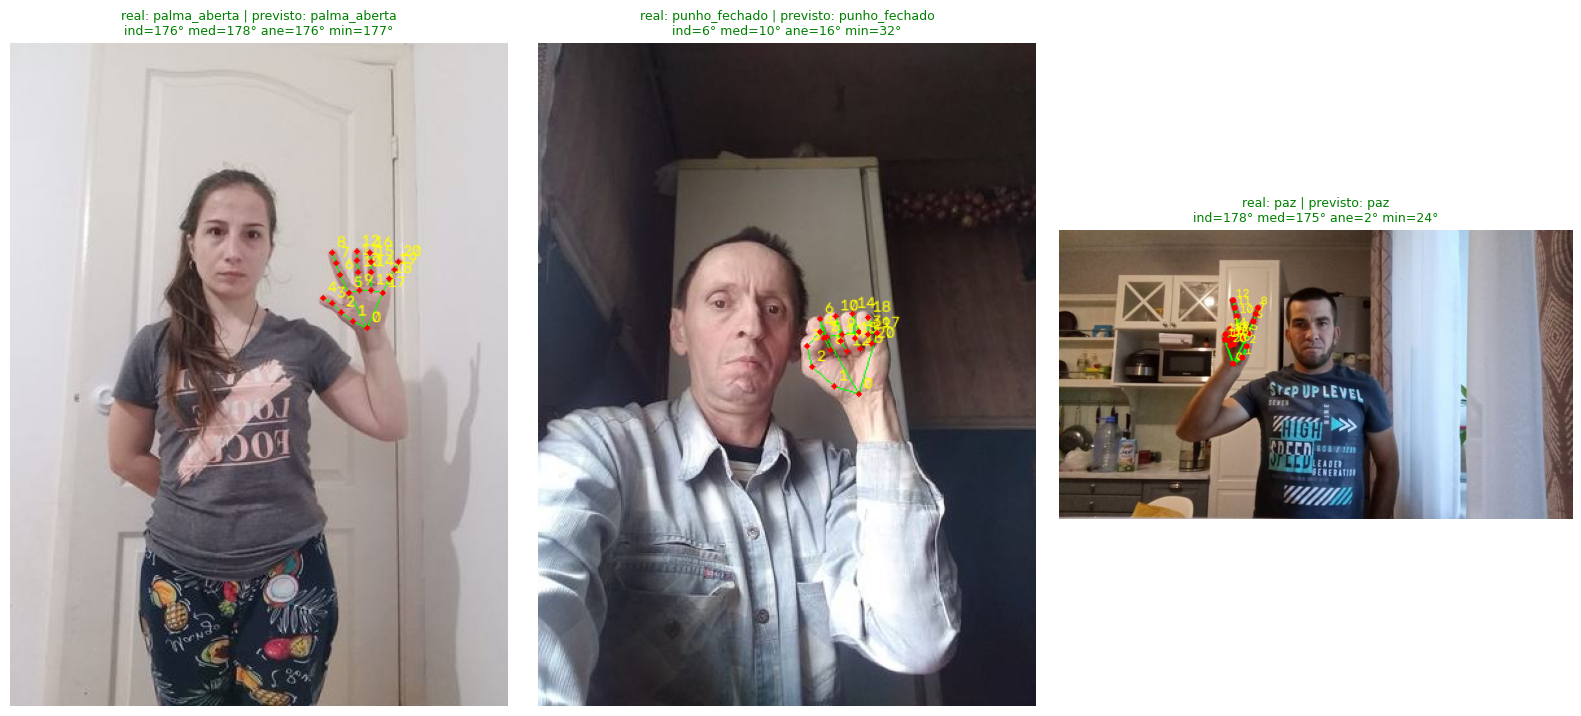

In [ ]:
fig, eixos = plt.subplots(1, 3, figsize=(16, 7))
with criar_detector() as det_exp:
    for ax, classe in zip(eixos, CLASSES):
        caminho = amostra[(amostra["conjunto"] == "calibracao") & (amostra["rotulo_real"] == classe)]["caminho"].iloc[0]
        r = processar_imagem(caminho, det_exp, limiar=150)
        ax.axis("off")
        if r["landmarks"] is None:
            ax.imshow(r["imagem"])
            ax.set_title(f"{classe}\nmão não detectada", color="red")
            continue
        ax.imshow(desenhar_landmarks(r["imagem"], r["landmarks"]))
        ok = r["previsao"] == classe
        angs = " ".join(f"{k.split('_')[1][:3]}={v:.0f}°" for k, v in r["caracteristicas"].items() if v is not None)
        ax.set_title(f"real: {classe} | previsto: {r['previsao']}\n{angs}", color="green" if ok else "red", fontsize=9)
plt.tight_layout(); plt.show()

### 4.7 Processamento em lote

Detecção e ângulos rodam **uma vez por imagem**, que é a etapa cara. A calibração e o teste trabalham sobre a tabela de ângulos. Imagem sem mão fica registrada com `mao_detectada=False` e ângulos vazios, e erro de leitura não interrompe o lote.

In [ ]:
def processar_lote(amostra):
    linhas = []
    with criar_detector() as detector:
        for k, r in enumerate(amostra.itertuples(), 1):
            linha = {"conjunto": r.conjunto, "caminho": r.caminho, "usuario": r.user_id,
                     "rotulo_real": r.rotulo_real, "mao_detectada": False,
                     "lateralidade": None, "largura": np.nan, "altura": np.nan,
                     **{c: np.nan for c in COLUNAS_ANG}, "erro": ""}
            try:
                img, w, h = carregar_imagem(r.caminho)
                linha["largura"], linha["altura"] = w, h
                det = detectar_landmarks(img, detector)
                if det is None:
                    linha["erro"] = "nenhuma mão detectada"
                else:
                    linha["mao_detectada"] = True
                    linha["lateralidade"] = det["lateralidade"]
                    for nome, valor in extrair_caracteristicas(det["landmarks"], w, h).items():
                        linha[nome] = np.nan if valor is None else valor
            except Exception as e:
                linha["erro"] = f"{type(e).__name__}: {e}"
            linhas.append(linha)
            if k % 100 == 0:
                print(f"{k}/{len(amostra)} imagens processadas")
    return pd.DataFrame(linhas)

def aplicar_classificador(df, limiar):
    df = df.copy()
    df["limiar"] = limiar
    df["rotulo_previsto"] = [classificar_gesto(r, limiar) for r in df[COLUNAS_ANG].to_dict("records")]
    df["acertou"] = df["rotulo_previsto"] == df["rotulo_real"]
    return df

caracteristicas_df = processar_lote(amostra)

resumo = caracteristicas_df.groupby("conjunto").agg(imagens=("caminho", "count"),
                                                    maos_detectadas=("mao_detectada", "sum"))
resumo["falhas_de_deteccao"] = resumo["imagens"] - resumo["maos_detectadas"]
display(resumo)
por_classe_det = caracteristicas_df.pivot_table(index="conjunto", columns="rotulo_real",
                                                values="mao_detectada", aggfunc="mean")[CLASSES]
print("Taxa de detecção por classe:")
display(por_classe_det.round(3))
falhas = caracteristicas_df[~caracteristicas_df["mao_detectada"]]
if len(falhas):
    print("Registros sem detecção (mantidos na avaliação como erro):")
    display(falhas[["conjunto", "rotulo_real", "erro", "caminho"]].head(20))

100/600 imagens processadas
200/600 imagens processadas
300/600 imagens processadas
400/600 imagens processadas
500/600 imagens processadas
600/600 imagens processadas


,imagens,maos_detectadas,falhas_de_deteccao
conjunto,,,
calibracao,300,284,16
teste,300,274,26


Taxa de detecção por classe:


rotulo_real,palma_aberta,punho_fechado,paz
conjunto,,,
calibracao,0.96,0.92,0.96
teste,0.96,0.92,0.86


Registros sem detecção (mantidos na avaliação como erro):


,conjunto,rotulo_real,erro,caminho
7,calibracao,palma_aberta,nenhuma mão detectada,/content/dataset_gestos/calibracao/palma_abert...
10,calibracao,palma_aberta,nenhuma mão detectada,/content/dataset_gestos/calibracao/palma_abert...
13,calibracao,palma_aberta,nenhuma mão detectada,/content/dataset_gestos/calibracao/palma_abert...
39,calibracao,palma_aberta,nenhuma mão detectada,/content/dataset_gestos/calibracao/palma_abert...
117,calibracao,punho_fechado,nenhuma mão detectada,/content/dataset_gestos/calibracao/punho_fecha...
126,calibracao,punho_fechado,nenhuma mão detectada,/content/dataset_gestos/calibracao/punho_fecha...
149,calibracao,punho_fechado,nenhuma mão detectada,/content/dataset_gestos/calibracao/punho_fecha...
155,calibracao,punho_fechado,nenhuma mão detectada,/content/dataset_gestos/calibracao/punho_fecha...
157,calibracao,punho_fechado,nenhuma mão detectada,/content/dataset_gestos/calibracao/punho_fecha...
158,calibracao,punho_fechado,nenhuma mão detectada,/content/dataset_gestos/calibracao/punho_fecha...


## 5. Avaliação

### 5.1 Calibração do limiar

Distribuição dos ângulos por classe na calibração (mãos detectadas). Mostra se existe separação entre dedo dobrado e estendido.

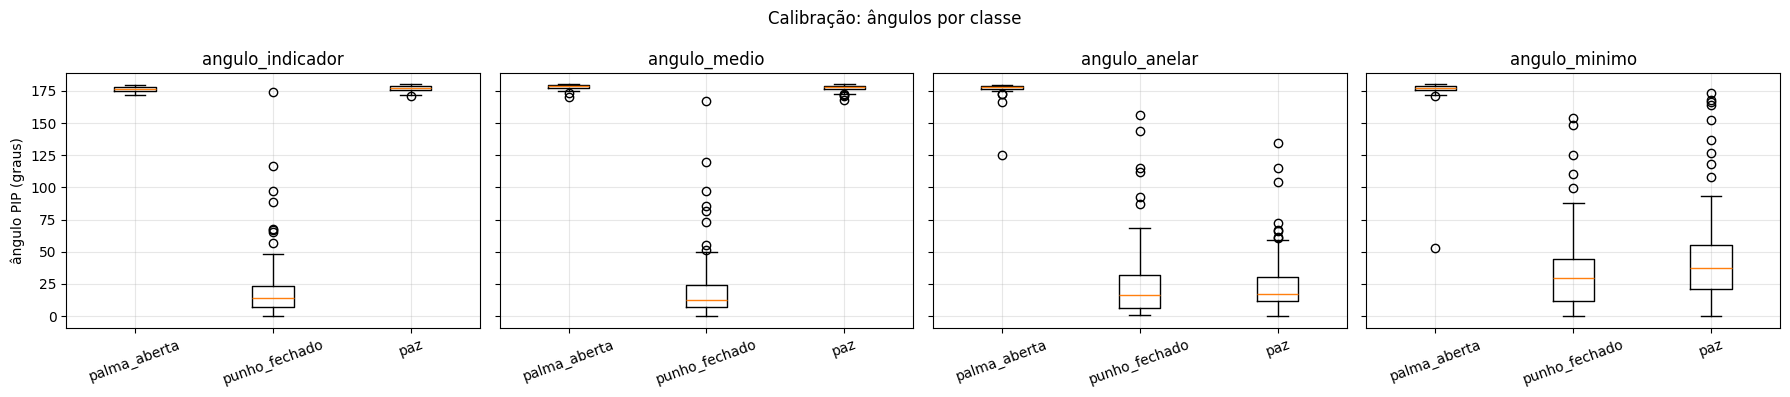

In [ ]:
cal = caracteristicas_df[(caracteristicas_df["conjunto"] == "calibracao") & caracteristicas_df["mao_detectada"]]
fig, eixos = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, col in zip(eixos, COLUNAS_ANG):
    dados = [cal.loc[cal["rotulo_real"] == c, col].dropna().values for c in CLASSES]
    ax.boxplot(dados)
    ax.set_xticks(range(1, len(CLASSES) + 1))
    ax.set_xticklabels(CLASSES, rotation=20)
    ax.set_title(col); ax.grid(alpha=0.3)
eixos[0].set_ylabel("ângulo PIP (graus)")
plt.suptitle("Calibração: ângulos por classe")
plt.tight_layout(); plt.show()

Limiares testados: 130, 140, 150, 160 e 170 graus, **apenas na calibração**. A acurácia conta `nao_reconhecido` e falhas de detecção como erro. **Critério:** maior acurácia; em empate, menos `nao_reconhecido`; persistindo o empate, o limiar mais próximo de 150°.

,limiar,acuracia,nao_reconhecido,imagens
0,130,0.913,24,300
1,140,0.917,24,300
2,150,0.920,23,300
3,160,0.923,22,300
4,170,0.930,20,300


Limiar escolhido: 170° (acurácia na calibração: 0.930)


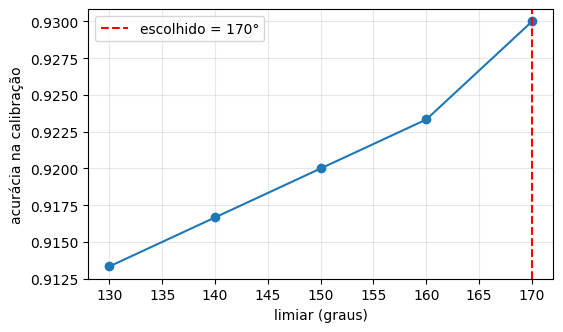

Matriz de confusão na calibração (linhas = real, colunas = previsto):


rotulo_previsto,nao_reconhecido,palma_aberta,paz,punho_fechado
rotulo_real,,,,
palma_aberta,5,94,1,0
punho_fechado,9,0,0,91
paz,6,0,94,0


In [ ]:
LIMIARES = [130, 140, 150, 160, 170]
df_cal = caracteristicas_df[caracteristicas_df["conjunto"] == "calibracao"]

linhas = []
for lim in LIMIARES:
    p = aplicar_classificador(df_cal, lim)
    linhas.append({"limiar": lim, "acuracia": p["acertou"].mean(),
                   "nao_reconhecido": int((p["rotulo_previsto"] == NAO_RECONHECIDO).sum()),
                   "imagens": len(p)})
tabela_cal = pd.DataFrame(linhas)
display(tabela_cal.style.format({"acuracia": "{:.3f}"}))

ordenada = tabela_cal.assign(dist=(tabela_cal["limiar"] - 150).abs()) \
                     .sort_values(["acuracia", "nao_reconhecido", "dist"], ascending=[False, True, True])
LIMIAR = int(ordenada.iloc[0]["limiar"])      # congelado a partir daqui
ACC_CAL = float(tabela_cal.loc[tabela_cal["limiar"] == LIMIAR, "acuracia"].iloc[0])
print(f"Limiar escolhido: {LIMIAR}° (acurácia na calibração: {ACC_CAL:.3f})")

plt.figure(figsize=(6, 3.5))
plt.plot(tabela_cal["limiar"], tabela_cal["acuracia"], marker="o")
plt.axvline(LIMIAR, color="r", ls="--", label=f"escolhido = {LIMIAR}°")
plt.xlabel("limiar (graus)"); plt.ylabel("acurácia na calibração"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

cal_pred = aplicar_classificador(df_cal, LIMIAR)
print("Matriz de confusão na calibração (linhas = real, colunas = previsto):")
display(pd.crosstab(cal_pred["rotulo_real"], cal_pred["rotulo_previsto"]).reindex(index=CLASSES))

### 5.2 Avaliação final no teste

O limiar está congelado. O conjunto `teste` é avaliado **uma vez**.

- A acurácia considera **todas** as imagens. Falhas de detecção e `nao_reconhecido` contam como erro da classe real.
- Na matriz de confusão, `nao_reconhecido` aparece como coluna extra.
- O `classification_report` cobre as três classes-alvo. `nao_reconhecido` reduz o recall da classe real e não afeta a precisão das outras.
- O intervalo de 95% da acurácia é o de Wilson.

Limiar: 170° | imagens de teste: 300
Acurácia geral: 0.873 (262/300) | IC 95% (Wilson): [0.831, 0.906]
Falhas de detecção de mão: 26/300
Previsões 'nao_reconhecido': 37

               precision    recall  f1-score   support

 palma_aberta       1.00      0.92      0.96       100
punho_fechado       0.99      0.92      0.95       100
          paz       1.00      0.78      0.88       100

    micro avg       1.00      0.87      0.93       300
    macro avg       1.00      0.87      0.93       300
 weighted avg       1.00      0.87      0.93       300



,imagens,maos_detectadas,acertos,recall
rotulo_real,,,,
palma_aberta,100,96,92,0.92
punho_fechado,100,92,92,0.92
paz,100,86,78,0.78


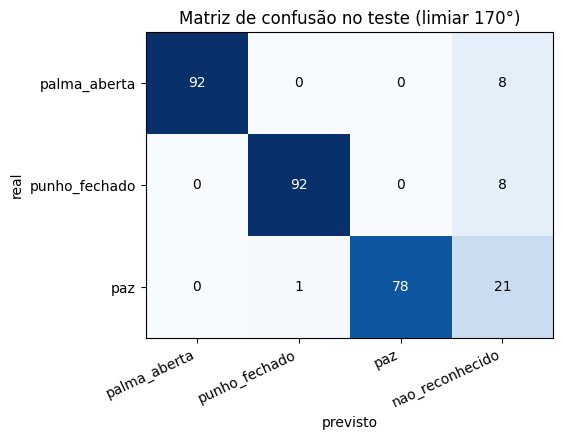

In [ ]:
def intervalo_wilson(k, n, z=1.96):
    p = k / n
    den = 1 + z * z / n
    centro = (p + z * z / (2 * n)) / den
    margem = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return centro - margem, centro + margem

df_teste = aplicar_classificador(caracteristicas_df[caracteristicas_df["conjunto"] == "teste"], LIMIAR)
n_teste = len(df_teste)
acertos = int(df_teste["acertou"].sum())
acc = acertos / n_teste
ic_baixo, ic_alto = intervalo_wilson(acertos, n_teste)
falhas_det = int((~df_teste["mao_detectada"]).sum())

print(f"Limiar: {LIMIAR}° | imagens de teste: {n_teste}")
print(f"Acurácia geral: {acc:.3f} ({acertos}/{n_teste}) | IC 95% (Wilson): [{ic_baixo:.3f}, {ic_alto:.3f}]")
print(f"Falhas de detecção de mão: {falhas_det}/{n_teste}")
print(f"Previsões 'nao_reconhecido': {(df_teste['rotulo_previsto'] == NAO_RECONHECIDO).sum()}\n")
print(classification_report(df_teste["rotulo_real"], df_teste["rotulo_previsto"], labels=CLASSES, zero_division=0))

por_classe = df_teste.groupby("rotulo_real").agg(imagens=("caminho", "count"),
                                                 maos_detectadas=("mao_detectada", "sum"),
                                                 acertos=("acertou", "sum")).reindex(CLASSES)
por_classe["recall"] = por_classe["acertos"] / por_classe["imagens"]
display(por_classe.round(3))

colunas = CLASSES + [NAO_RECONHECIDO]
cm = confusion_matrix(df_teste["rotulo_real"], df_teste["rotulo_previsto"], labels=colunas)[:len(CLASSES), :]
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(colunas))); ax.set_xticklabels(colunas, rotation=25, ha="right")
ax.set_yticks(range(len(CLASSES))); ax.set_yticklabels(CLASSES)
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xlabel("previsto"); ax.set_ylabel("real"); ax.set_title(f"Matriz de confusão no teste (limiar {LIMIAR}°)")
plt.tight_layout(); plt.show()

### 5.3 Análise de erros

Cada erro do teste é classificado por tipo (sem detecção, padrão não reconhecido ou confusão com outra classe). A figura mostra até 12 erros com os landmarks e os ângulos.

38 erro(s) em 300 imagens de teste.


,erros
sem detecção,26
padrão não reconhecido,11
confundido com outra classe,1


,rotulo_real,rotulo_previsto,mao_detectada,angulo_indicador,angulo_medio,angulo_anelar,angulo_minimo,caminho
0,palma_aberta,nao_reconhecido,False,NaN,NaN,NaN,NaN,/content/dataset_gestos/teste/palma_aberta/20b...
1,palma_aberta,nao_reconhecido,False,NaN,NaN,NaN,NaN,/content/dataset_gestos/teste/palma_aberta/827...
2,palma_aberta,nao_reconhecido,True,177.9,177.4,177.9,169.1,/content/dataset_gestos/teste/palma_aberta/123...
3,palma_aberta,nao_reconhecido,False,NaN,NaN,NaN,NaN,/content/dataset_gestos/teste/palma_aberta/457...
4,palma_aberta,nao_reconhecido,True,175.9,174.1,169.5,173.5,/content/dataset_gestos/teste/palma_aberta/980...
5,palma_aberta,nao_reconhecido,True,179.8,178.4,177.6,168.7,/content/dataset_gestos/teste/palma_aberta/d3e...
6,palma_aberta,nao_reconhecido,True,165.1,179.6,173.9,176.4,/content/dataset_gestos/teste/palma_aberta/3df...
7,palma_aberta,nao_reconhecido,False,NaN,NaN,NaN,NaN,/content/dataset_gestos/teste/palma_aberta/20e...
8,punho_fechado,nao_reconhecido,False,NaN,NaN,NaN,NaN,/content/dataset_gestos/teste/punho_fechado/7c...
9,punho_fechado,nao_reconhecido,False,NaN,NaN,NaN,NaN,/content/dataset_gestos/teste/punho_fechado/7f...


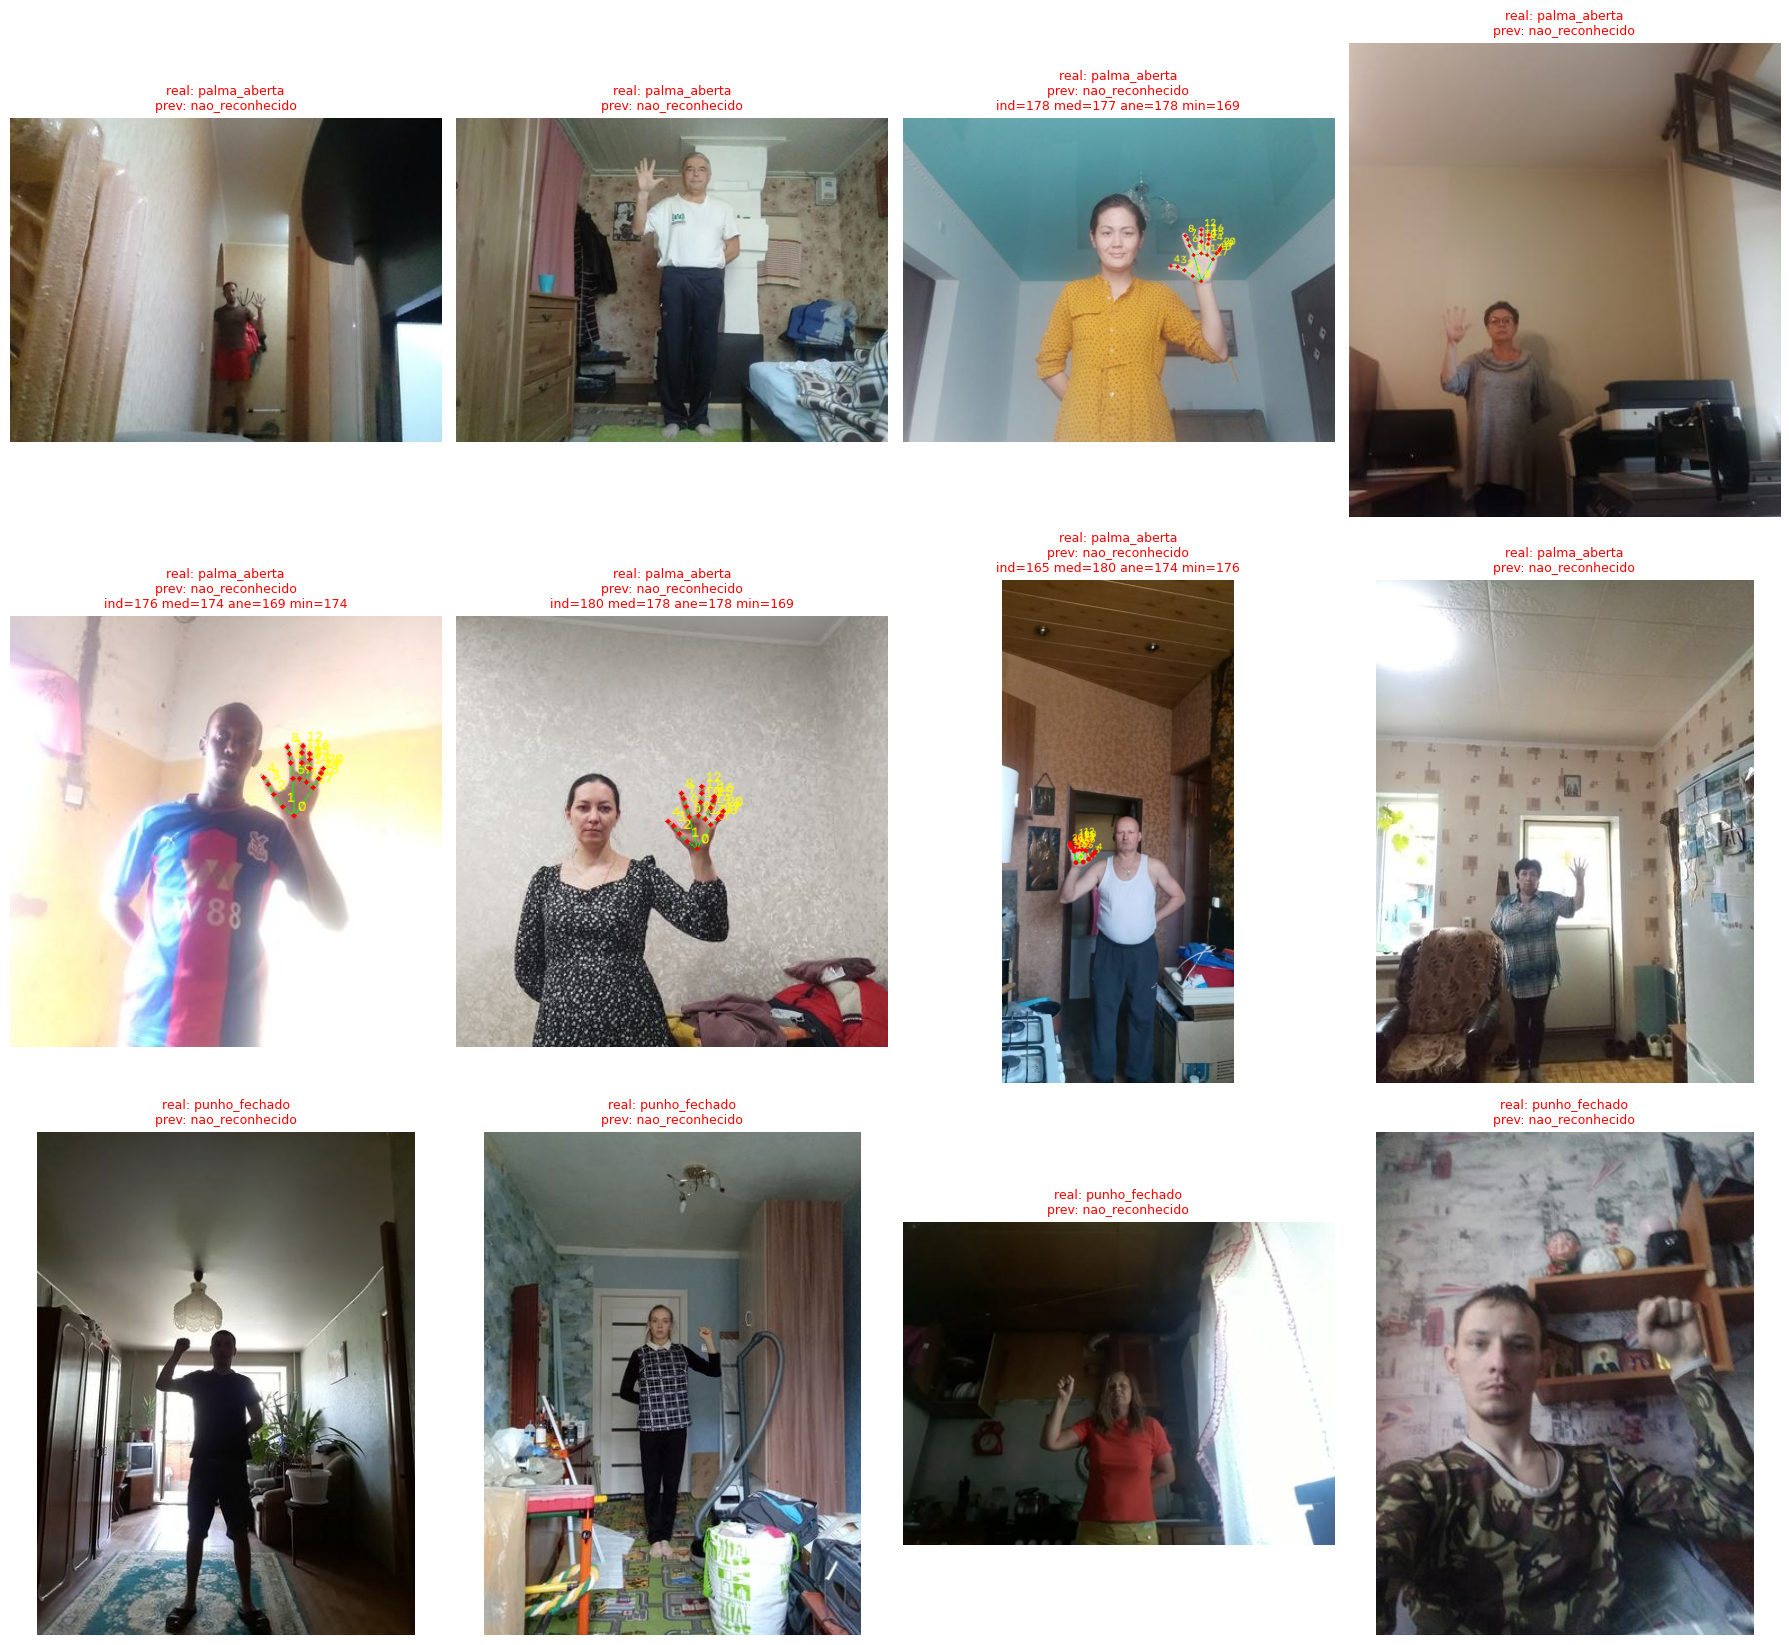

In [ ]:
erros = df_teste[~df_teste["acertou"]].reset_index(drop=True)
print(f"{len(erros)} erro(s) em {n_teste} imagens de teste.")
if len(erros):
    tipo = np.where(~erros["mao_detectada"], "sem detecção",
                    np.where(erros["rotulo_previsto"] == NAO_RECONHECIDO, "padrão não reconhecido",
                             "confundido com outra classe"))
    display(pd.Series(tipo).value_counts().rename("erros").to_frame())
    display(erros[["rotulo_real", "rotulo_previsto", "mao_detectada"] + COLUNAS_ANG + ["caminho"]].round(1))

    mostrar = erros.head(12)
    cols = min(4, len(mostrar)); lin = math.ceil(len(mostrar) / cols)
    fig, eixos = plt.subplots(lin, cols, figsize=(4.5 * cols, 5.5 * lin), squeeze=False)
    for ax in eixos.ravel():
        ax.axis("off")
    with criar_detector() as det_err:
        for ax, (_, r) in zip(eixos.ravel(), mostrar.iterrows()):
            res = processar_imagem(r["caminho"], det_err, LIMIAR)
            ax.imshow(desenhar_landmarks(res["imagem"], res["landmarks"]) if res["landmarks"] else res["imagem"])
            angs = "" if res["caracteristicas"] is None else "\n" + " ".join(
                f"{k.split('_')[1][:3]}={v:.0f}" for k, v in res["caracteristicas"].items() if v is not None)
            ax.set_title(f"real: {r['rotulo_real']}\nprev: {r['rotulo_previsto']}{angs}", fontsize=9, color="red")
    plt.tight_layout(); plt.show()

### 5.4 Exportação e contrato para Flutter/Dart

Saídas em um único ZIP (`saidas_gestos.zip`): resultados por imagem com os ângulos (para comparar Colab e app), amostra do HaGRID usada, regras e contrato. O modelo de landmarks não é exportado, porque o app já tem `hand_landmarker.task` em `android/app/src/main/assets/`.

In [ ]:
resultados = pd.concat([aplicar_classificador(caracteristicas_df[caracteristicas_df["conjunto"] == "calibracao"], LIMIAR),
                        df_teste], ignore_index=True)
resultados.to_csv("/content/resultados_gestos.csv", index=False)
amostra.drop(columns=["rotulos"]).to_csv("/content/amostra_hagrid.csv", index=False)

regras = pd.DataFrame([
    {"gesto": "palma_aberta",  "regra": "indicador, medio, anelar e minimo estendidos"},
    {"gesto": "paz",           "regra": "indicador e medio estendidos; anelar e minimo dobrados"},
    {"gesto": "punho_fechado", "regra": "indicador, medio, anelar e minimo dobrados"},
    {"gesto": NAO_RECONHECIDO, "regra": "qualquer outro padrao, angulo ausente ou sem mao"},
])
regras["limiar_graus"] = LIMIAR
regras["estendido_se"] = "angulo >= limiar"
regras.to_csv("/content/regras_gestos.csv", index=False)
display(regras)

,gesto,regra,limiar_graus,estendido_se
0,palma_aberta,"indicador, medio, anelar e minimo estendidos",170,angulo >= limiar
1,paz,indicador e medio estendidos; anelar e minimo ...,170,angulo >= limiar
2,punho_fechado,"indicador, medio, anelar e minimo dobrados",170,angulo >= limiar
3,nao_reconhecido,"qualquer outro padrao, angulo ausente ou sem mao",170,angulo >= limiar


**Contrato do classificador para Flutter/Dart.** A célula gera o contrato com o limiar escolhido. Os casos de teste têm a saída esperada calculada pela função `classificar_gesto` deste notebook.

In [ ]:
def _fmt(v):
    return "null" if v is None else f"{v:g}"

L = LIMIAR
casos_teste = [
    ("4 dedos estendidos",             [L + 25, L + 25, L + 25, L + 25]),
    ("4 dedos dobrados",               [L - 40, L - 40, L - 40, L - 40]),
    ("indicador e médio estendidos",   [L + 25, L + 25, L - 40, L - 40]),
    ("só indicador estendido",         [L + 25, L - 40, L - 40, L - 40]),
    ("anelar e mínimo estendidos",     [L - 40, L - 40, L + 25, L + 25]),
    ("exatamente no limiar (>=)",      [L, L, L, L]),
    ("ângulo ausente (mínimo = null)", [L + 25, L + 25, L + 25, None]),
    ("sem mão detectada",              [None, None, None, None]),
]
linhas_md = "\n".join(
    f"| {desc} | {', '.join(_fmt(a) for a in angs)} | `{classificar_gesto(dict(zip(COLUNAS_ANG, angs)), L)}` |"
    for desc, angs in casos_teste)

contrato = f"""### Contrato do classificador para Flutter/Dart

**Entrada.** Lista de 21 `HandPoint(x, y, z)` normalizados (x e y em [0, 1]), mais a **largura** e a **altura** em pixels da imagem, com orientação EXIF já corrigida.

**Ângulo.** Para cada dedo, com A, B e C em pixels (`px = x * largura`, `py = y * altura`; nunca calcular em x/y normalizados sem esta correção):

`theta = acos( ((A-B)·(C-B)) / (|A-B| · |C-B|) )`, em graus. Limitar o cosseno a [-1, 1] antes do `acos`. Se `|A-B| · |C-B| < 1e-6`, o ângulo é `null`.

**Landmarks (A, B, C; articulação em B).**
- indicador: (5, 6, 7)
- médio: (9, 10, 11)
- anelar: (13, 14, 15)
- mínimo: (17, 18, 19)

**Limiar (escolhido só na calibração):** `{L}` graus. Dedo estendido se `ângulo >= {L}`.

**Regras (o polegar é ignorado).**
1. 4 dedos estendidos → `palma_aberta`
2. indicador e médio estendidos, anelar e mínimo dobrados → `paz`
3. 4 dedos dobrados → `punho_fechado`
4. qualquer outro padrão → `nao_reconhecido`

**Sem mão ou ângulo inválido.** Sem mão, ou qualquer um dos 4 ângulos `null` ou NaN → `nao_reconhecido`.

**Saídas exatas:** `palma_aberta`, `punho_fechado`, `paz`, `nao_reconhecido`.

**Casos de teste (ângulos em graus: indicador, médio, anelar, mínimo).**

| Caso | Ângulos | Saída esperada |
|---|---|---|
{linhas_md}

**Integração.** Serviço de domínio (`GestureRecognitionService`) que recebe `List<HandPoint>`, largura e altura e devolve o enum. O `MethodChannel` `br.edu.ifpe.mobile.mediapipe/hand_tracking` e o código Kotlin ficam como estão. Controller e UI exibem o gesto além dos landmarks. Conferência: as mesmas fotos no Colab e no app, comparando os ângulos e a saída com `resultados_gestos.csv`.
"""
display(Markdown(contrato))
Path("/content/contrato_flutter_dart.md").write_text(contrato, encoding="utf-8")

with zipfile.ZipFile("/content/saidas_gestos.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for nome in ["resultados_gestos.csv", "amostra_hagrid.csv", "regras_gestos.csv", "contrato_flutter_dart.md"]:
        z.write(f"/content/{nome}", nome)
files.download("/content/saidas_gestos.zip")

### Contrato do classificador para Flutter/Dart

**Entrada.** Lista de 21 `HandPoint(x, y, z)` normalizados (x e y em [0, 1]), mais a **largura** e a **altura** em pixels da imagem, com orientação EXIF já corrigida.

**Ângulo.** Para cada dedo, com A, B e C em pixels (`px = x * largura`, `py = y * altura`; nunca calcular em x/y normalizados sem esta correção):

`theta = acos( ((A-B)·(C-B)) / (|A-B| · |C-B|) )`, em graus. Limitar o cosseno a [-1, 1] antes do `acos`. Se `|A-B| · |C-B| < 1e-6`, o ângulo é `null`.

**Landmarks (A, B, C; articulação em B).**
- indicador: (5, 6, 7)
- médio: (9, 10, 11)
- anelar: (13, 14, 15)
- mínimo: (17, 18, 19)

**Limiar (escolhido só na calibração):** `170` graus. Dedo estendido se `ângulo >= 170`.

**Regras (o polegar é ignorado).**
1. 4 dedos estendidos → `palma_aberta`
2. indicador e médio estendidos, anelar e mínimo dobrados → `paz`
3. 4 dedos dobrados → `punho_fechado`
4. qualquer outro padrão → `nao_reconhecido`

**Sem mão ou ângulo inválido.** Sem mão, ou qualquer um dos 4 ângulos `null` ou NaN → `nao_reconhecido`.

**Saídas exatas:** `palma_aberta`, `punho_fechado`, `paz`, `nao_reconhecido`.

**Casos de teste (ângulos em graus: indicador, médio, anelar, mínimo).**

| Caso | Ângulos | Saída esperada |
|---|---|---|
| 4 dedos estendidos | 195, 195, 195, 195 | `palma_aberta` |
| 4 dedos dobrados | 130, 130, 130, 130 | `punho_fechado` |
| indicador e médio estendidos | 195, 195, 130, 130 | `paz` |
| só indicador estendido | 195, 130, 130, 130 | `nao_reconhecido` |
| anelar e mínimo estendidos | 130, 130, 195, 195 | `nao_reconhecido` |
| exatamente no limiar (>=) | 170, 170, 170, 170 | `palma_aberta` |
| ângulo ausente (mínimo = null) | 195, 195, 195, null | `nao_reconhecido` |
| sem mão detectada | null, null, null, null | `nao_reconhecido` |

**Integração.** Serviço de domínio (`GestureRecognitionService`) que recebe `List<HandPoint>`, largura e altura e devolve o enum. O `MethodChannel` `br.edu.ifpe.mobile.mediapipe/hand_tracking` e o código Kotlin ficam como estão. Controller e UI exibem o gesto além dos landmarks. Conferência: as mesmas fotos no Colab e no app, comparando os ângulos e a saída com `resultados_gestos.csv`.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 6. Ética e privacidade

- **Origem e licença.** As imagens são do HaGRID (Kapitanov, Makhlyarchuk e Kvanchiani), licença CC BY-SA 4.0, com atribuição aos autores. O notebook baixa o dataset do Hugging Face e não o redistribui.
- **Pessoas nas imagens.** As fotos mostram pessoas reais. O notebook usa só o rótulo e o `user_id` pseudonimizado que acompanha o dataset, para separar calibração e teste. As imagens ficam apenas na sessão do Colab e nenhuma é exportada: os arquivos de saída contêm caminhos, ângulos e identificadores pseudonimizados.
- **Quem pode ser mais prejudicado.** O sistema não foi avaliado por grupo demográfico. Mãos de tons de pele, tamanhos e condições pouco representados na amostra (por exemplo, dedos com mobilidade limitada) podem ter desempenho pior. Isso exige teste próprio antes de qualquer uso real.
- **Alcance.** São três poses estáticas simplificadas. O sistema não reconhece linguagem de sinais.

## 7. Conclusão

A célula abaixo escreve a conclusão a partir dos números desta execução.

In [ ]:
n_det = int(df_teste["mao_detectada"].sum())
rec = por_classe["recall"]
detectadas_erradas = df_teste[df_teste["mao_detectada"] & ~df_teste["acertou"]]
confusoes = (detectadas_erradas[detectadas_erradas["rotulo_previsto"] != NAO_RECONHECIDO]
             .groupby(["rotulo_real", "rotulo_previsto"]).size().sort_values(ascending=False))
n_nr = int((detectadas_erradas["rotulo_previsto"] == NAO_RECONHECIDO).sum())

if len(confusoes):
    (real, prev), qtd = confusoes.index[0], int(confusoes.iloc[0])
    frase_conf = f"A confusão entre classes mais frequente foi `{real}` previsto como `{prev}` ({qtd} casos)."
else:
    frase_conf = "Não houve confusão entre classes nas mãos detectadas."

conclusao = f"""
**Detecção.** O MediaPipe encontrou a mão em {n_det} das {n_teste} imagens de teste ({n_det / n_teste:.1%}). As {falhas_det} falhas contam como erro na acurácia.

**Limiar.** Foi escolhido {LIMIAR}° pela maior acurácia na calibração ({ACC_CAL:.1%} em {len(df_cal)} imagens), sem usar o teste.

**Desempenho no teste.** Acurácia de {acc:.1%} ({acertos}/{n_teste}), com intervalo de 95% entre {ic_baixo:.1%} e {ic_alto:.1%}. Recall por classe: {', '.join(f'`{c}` {rec[c]:.1%}' for c in CLASSES)}. O gesto com menor recall foi `{rec.idxmin()}`.

**Erros.** {len(erros)} no total: {falhas_det} sem detecção, {n_nr} com padrão não reconhecido pelas regras e {len(detectadas_erradas) - n_nr} confundidos com outra classe. {frase_conf}

**Limitações.**
- O polegar não entra nas regras.
- O ângulo é medido em 2D no plano da imagem. Dedos apontados para a câmera ficam encurtados e alteram o ângulo.
- A avaliação usa {n_teste} imagens de uma amostra reduzida (384p) do HaGRID, com uma única mão por imagem e poses encenadas.
- Não há avaliação por grupo demográfico.

**Com mais tempo.**
- Adicionar uma característica do polegar e ângulos de outras articulações (MCP e DIP) ou a distância entre a ponta e a base de cada dedo.
- Repetir a avaliação com mais imagens do HaGRID completo.
- Portar as regras para Dart e comparar as saídas do app com `resultados_gestos.csv`.
"""
display(Markdown(conclusao))


**Detecção.** O MediaPipe encontrou a mão em 274 das 300 imagens de teste (91.3%). As 26 falhas contam como erro na acurácia.

**Limiar.** Foi escolhido 170° pela maior acurácia na calibração (93.0% em 300 imagens), sem usar o teste.

**Desempenho no teste.** Acurácia de 87.3% (262/300), com intervalo de 95% entre 83.1% e 90.6%. Recall por classe: `palma_aberta` 92.0%, `punho_fechado` 92.0%, `paz` 78.0%. O gesto com menor recall foi `paz`.

**Erros.** 38 no total: 26 sem detecção, 11 com padrão não reconhecido pelas regras e 1 confundidos com outra classe. A confusão entre classes mais frequente foi `paz` previsto como `punho_fechado` (1 casos).

**Limitações.**
- O polegar não entra nas regras.
- O ângulo é medido em 2D no plano da imagem. Dedos apontados para a câmera ficam encurtados e alteram o ângulo.
- A avaliação usa 300 imagens de uma amostra reduzida (384p) do HaGRID, com uma única mão por imagem e poses encenadas.
- Não há avaliação por grupo demográfico.

**Com mais tempo.**
- Adicionar uma característica do polegar e ângulos de outras articulações (MCP e DIP) ou a distância entre a ponta e a base de cada dedo.
- Repetir a avaliação com mais imagens do HaGRID completo.
- Portar as regras para Dart e comparar as saídas do app com `resultados_gestos.csv`.
